Exploration du dataset MRI Brain Tumor

In [8]:
from pathlib import Path

chemin_dataset = Path(r"C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data")

print("Chemin utilisé :", chemin_dataset)
print("Le dossier existe :", chemin_dataset.exists())

if chemin_dataset.exists() and chemin_dataset.is_dir():
    for element in chemin_dataset.iterdir():
        if element.is_dir():
            print("[Dossier]", element.name)
        else:
            print("[Fichier]", element.name)

Chemin utilisé : C:\Users\Olaya\Desktop\sprint_2\neuroscan-ai\data
Le dossier existe : True
[Dossier] Train
[Dossier] Val


In [9]:
for nom_dossier in ["Train", "Val"]:
    dossier = chemin_dataset / nom_dossier

    print(f"\nContenu de {nom_dossier} :")
    for element in dossier.iterdir():
        if element.is_dir():
            print("[Dossier]", element.name)
        else:
            print("[Fichier]", element.name)


Contenu de Train :
[Dossier] Glioma
[Dossier] Meningioma
[Dossier] No Tumor
[Dossier] Pituitary

Contenu de Val :
[Dossier] Glioma
[Dossier] Meningioma
[Dossier] No Tumor
[Dossier] Pituitary


In [10]:
from collections import Counter

extensions_par_classe = {}

for nom_split in ["Train", "Val"]:
    dossier_split = chemin_dataset / nom_split

    for nom_classe in ["Glioma", "Meningioma", "No Tumor", "Pituitary"]:
        dossier_classe = dossier_split / nom_classe
        fichiers = [f for f in dossier_classe.iterdir() if f.is_file()]

        extensions = Counter(f.suffix.lower() for f in fichiers)
        print(f"{nom_split} / {nom_classe} : {len(fichiers)} fichiers — {dict(extensions)}")

Train / Glioma : 0 fichiers — {}
Train / Meningioma : 0 fichiers — {}
Train / No Tumor : 0 fichiers — {}
Train / Pituitary : 0 fichiers — {}
Val / Glioma : 0 fichiers — {}
Val / Meningioma : 0 fichiers — {}
Val / No Tumor : 0 fichiers — {}
Val / Pituitary : 0 fichiers — {}


In [11]:
for nom_split in ["Train", "Val"]:
    dossier_split = chemin_dataset / nom_split
    print(f"\nFichiers trouvés dans {nom_split} :")

    for chemin in dossier_split.rglob("*"):
        if chemin.is_file():
            print(chemin.relative_to(chemin_dataset))


Fichiers trouvés dans Train :
Train\Pituitary\images\p (1).jpg
Train\Pituitary\images\p (10).jpg
Train\Pituitary\images\p (100).jpg
Train\Pituitary\images\p (101).jpg
Train\Pituitary\images\p (102).jpg
Train\Pituitary\images\p (103).jpg
Train\Pituitary\images\p (104).jpg
Train\Pituitary\images\p (105).jpg
Train\Pituitary\images\p (106).jpg
Train\Pituitary\images\p (107).jpg
Train\Pituitary\images\p (108).jpg
Train\Pituitary\images\p (109).jpg
Train\Pituitary\images\p (11).jpg
Train\Pituitary\images\p (110).jpg
Train\Pituitary\images\p (111).jpg
Train\Pituitary\images\p (112).jpg
Train\Pituitary\images\p (113).jpg
Train\Pituitary\images\p (114).jpg
Train\Pituitary\images\p (115).jpg
Train\Pituitary\images\p (116).jpg
Train\Pituitary\images\p (117).jpg
Train\Pituitary\images\p (118).jpg
Train\Pituitary\images\p (119).jpg
Train\Pituitary\images\p (12).jpg
Train\Pituitary\images\p (120).jpg
Train\Pituitary\images\p (121).jpg
Train\Pituitary\images\p (122).jpg
Train\Pituitary\images\p (123

In [12]:
for nom_split in ["Train", "Val"]:
    dossier_split = chemin_dataset / nom_split
    print(f"\n{nom_split} :")

    for nom_classe in ["Glioma", "Meningioma", "No Tumor", "Pituitary"]:
        dossier_classe = dossier_split / nom_classe
        print(f"  {nom_classe} :")

        for sous_dossier in dossier_classe.iterdir():
            if sous_dossier.is_dir():
                nombre_fichiers = sum(
                    1 for element in sous_dossier.rglob("*") if element.is_file()
                )
                print(f"    {sous_dossier.name} : {nombre_fichiers} fichiers")


Train :
  Glioma :
    images : 1153 fichiers
    labels : 1153 fichiers
  Meningioma :
    images : 1449 fichiers
    labels : 1449 fichiers
  No Tumor :
    images : 711 fichiers
    labels : 711 fichiers
  Pituitary :
    images : 1424 fichiers
    labels : 1424 fichiers

Val :
  Glioma :
    images : 136 fichiers
    labels : 136 fichiers
  Meningioma :
    images : 140 fichiers
    labels : 140 fichiers
  No Tumor :
    images : 100 fichiers
    labels : 100 fichiers
  Pituitary :
    images : 136 fichiers
    labels : 136 fichiers


In [13]:
dossier_labels = chemin_dataset / "Train" / "Glioma" / "labels"

fichiers_labels = sorted(dossier_labels.glob("*.txt"))

print("Nombre de fichiers .txt :", len(fichiers_labels))
print("\nExemples d'annotations :")

for fichier in fichiers_labels[:5]:
    print(f"\n{fichier.name}")
    print(fichier.read_text(encoding="utf-8").strip())

Nombre de fichiers .txt : 1153

Exemples d'annotations :

gg (1).txt
0 0.567383 0.519531 0.189453 0.148438

gg (103).txt
0 0.414062 0.490234 0.140625 0.132812

gg (104).txt
0 0.425781 0.486328 0.191406 0.164062

gg (105).txt
0 0.423828 0.477539 0.187500 0.173828

gg (106).txt
0 0.420898 0.463867 0.181641 0.150391


In [14]:
from PIL import Image

dossier_images = chemin_dataset / "Train" / "Glioma" / "images"
dossier_labels = chemin_dataset / "Train" / "Glioma" / "labels"

fichier_label = sorted(dossier_labels.glob("*.txt"))[0]
fichier_image = dossier_images / (fichier_label.stem + ".jpg")

print("Annotation :", fichier_label.name)
print("Image correspondante :", fichier_image.name)
print("L'image existe :", fichier_image.exists())
print("Contenu de l'annotation :", fichier_label.read_text(encoding="utf-8").strip())

if fichier_image.exists():
    with Image.open(fichier_image) as image:
        print("Dimensions de l'image (largeur, hauteur) :", image.size)
        print("Mode de couleur :", image.mode)

Annotation : gg (1).txt
Image correspondante : gg (1).jpg
L'image existe : True
Contenu de l'annotation : 0 0.567383 0.519531 0.189453 0.148438
Dimensions de l'image (largeur, hauteur) : (512, 512)
Mode de couleur : RGB


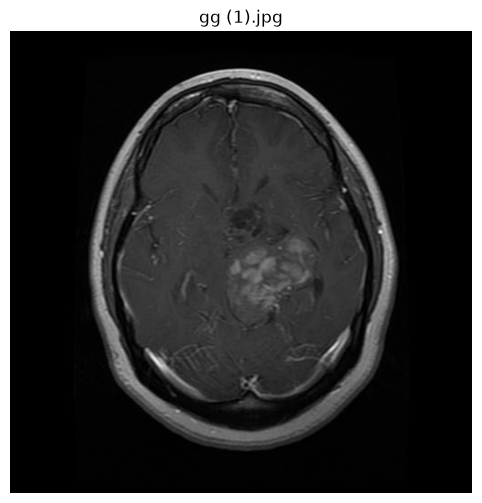

Valeurs de l'annotation : 0 0.567383 0.519531 0.189453 0.148438


In [15]:
import matplotlib.pyplot as plt

with Image.open(fichier_image) as image:
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(fichier_image.name)
    plt.axis("off")
    plt.show()

print("Valeurs de l'annotation :", fichier_label.read_text(encoding="utf-8").strip())

In [16]:
from PIL import Image

with Image.open(fichier_image) as image:
    print("Image lisible :", image.format)
    print("Dimensions :", image.size)
    print("Mode de couleur :", image.mode)

Image lisible : JPEG
Dimensions : (512, 512)
Mode de couleur : RGB


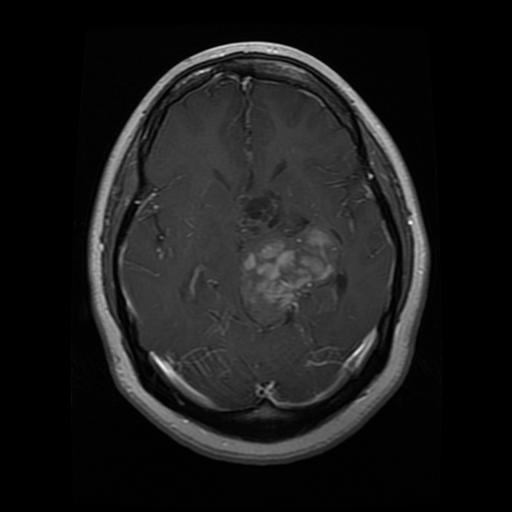

In [17]:
from IPython.display import display
from PIL import Image

image = Image.open(fichier_image)
display(image)

In [18]:
import os

os.startfile(str(fichier_image))

In [19]:
valeurs_annotation = fichier_label.read_text(encoding="utf-8").strip().split()
print("Valeurs du fichier :", valeurs_annotation)

Valeurs du fichier : ['0', '0.567383', '0.519531', '0.189453', '0.148438']


In [20]:
from PIL import Image, ImageDraw
import tempfile
import os

valeurs = fichier_label.read_text(encoding="utf-8").strip().split()

centre_x = float(valeurs[1]) * image.width
centre_y = float(valeurs[2]) * image.height
largeur = float(valeurs[3]) * image.width
hauteur = float(valeurs[4]) * image.height

x_min = centre_x - largeur / 2
y_min = centre_y - hauteur / 2
x_max = centre_x + largeur / 2
y_max = centre_y + hauteur / 2

image_avec_boite = image.copy()
dessin = ImageDraw.Draw(image_avec_boite)
dessin.rectangle((x_min, y_min, x_max, y_max), outline="red", width=3)

chemin_apercu = Path(tempfile.gettempdir()) / "apercu_annotation.jpg"
image_avec_boite.save(chemin_apercu)
os.startfile(str(chemin_apercu))

print("Aperçu enregistré dans :", chemin_apercu)
print("Boîte en pixels :", round(x_min), round(y_min), round(x_max), round(y_max))

Aperçu enregistré dans : C:\Users\Olaya\AppData\Local\Temp\apercu_annotation.jpg
Boîte en pixels : 242 228 339 304
